In [1]:

import sys
print(sys.executable)

/mpcdf/soft/SLE_15/packages/x86_64/anaconda/3/2023.03/bin/python


In [2]:
from astropy.io import fits
from astropy.visualization import ImageNormalize, AsinhStretch
import matplotlib.pyplot as plt
import numpy as np

In [3]:
data_file = "examples/ic3478rss_256.fits"
model_file = "examples/models/model.fits"
residual_file = "examples/resid/resid.fits"

data = fits.getdata(data_file).astype(float)
model = fits.getdata(model_file).astype(float)
residual = fits.getdata(residual_file).astype(float)


vmin, vmax = np.nanpercentile(data, [1, 99.7])

# Same normalization object used for BOTH images
norm = ImageNormalize(vmin=vmin,vmax=vmax,stretch=AsinhStretch())



# Symmetric limits around zero
res_limit = np.nanpercentile(np.abs(residual), 99)



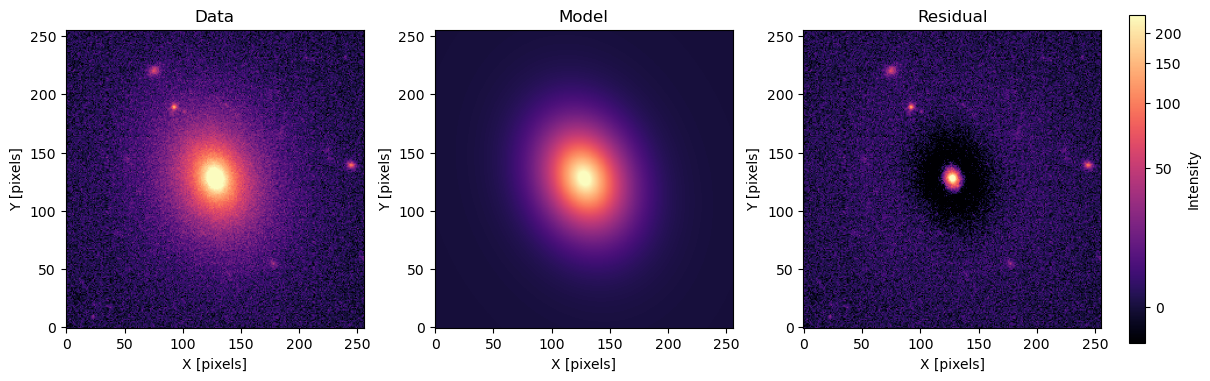

In [4]:

fig, axes = plt.subplots(1, 3, figsize=(12, 4), constrained_layout=True)

# DATA
im0 = axes[0].imshow( data, origin="lower", cmap="magma", norm=norm)
axes[0].set_title("Data")


# MODEL
im1 = axes[1].imshow( model, origin="lower", cmap="magma", norm=norm)
axes[1].set_title("Model")


# RESIDUAL
im2 = axes[2].imshow(residual,origin="lower",cmap="magma", norm=norm)
axes[2].set_title("Residual")



for ax in axes:
    ax.set_xlabel("X [pixels]")
    ax.set_ylabel("Y [pixels]")


# ONE shared colorbar for data + model
cbar1 = fig.colorbar(im0, ax=axes[:3],shrink=0.85,pad=0.02)
cbar1.set_label("Intensity")


plt.show()

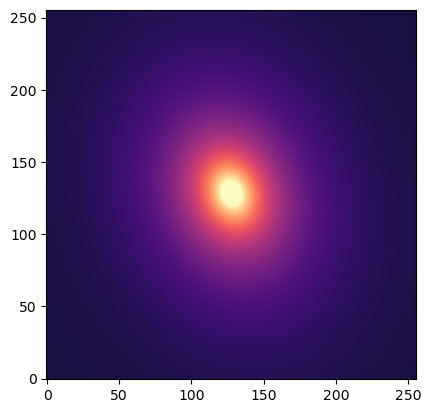

In [7]:
modelimage = "examples/modelimage.fits"

mod = fits.getdata(modelimage).astype(float)
plt.imshow( mod, origin="lower", cmap="magma", norm=norm)
plt.show()
